In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.inspection import permutation_importance, DecisionBoundaryDisplay

kepler = pd.read_csv("data/kepler.csv", comment="#")
labeled = kepler[kepler.koi_disposition.isin(["CONFIRMED", "FALSE POSITIVE"])]

## Data preparation

The NASA file starts with comment lines marked `#`, so we skip those. CANDIDATE rows don't have a known answer yet, so we keep only CONFIRMED and FALSE POSITIVE. We also drop the 363 rows with no fitted transit model, since missing values show up almost only in false positives and would give the answer away.

We leave out several columns on purpose. `koi_pdisposition`, `koi_score`, and the four `koi_fpflag` columns are outputs of NASA's own vetting process, so using them would basically copy the answer. The quick check below shows why.

In [12]:
# What does the data look like?
print(f"{data.shape[0]:,} KOIs, {data.shape[1]} columns, {data.kepid.nunique():,} stars, {header_lines} comment lines")

# Any duplicates?
print("Duplicate KOI names:", data.kepoi_name.duplicated().sum())

# What do our values look like?
data.koi_disposition.value_counts().to_frame("KOIs")

9,564 KOIs, 49 columns, 8,214 stars, 53 comment lines
Duplicate KOI names: 0


,KOIs
koi_disposition,
FALSE POSITIVE,4839
CONFIRMED,2748
CANDIDATE,1977


In [13]:
FEATURES = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",   # transit
            "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag",                         # host star
            "koi_prad", "koi_teq", "koi_insol"]                                         # derived planet values
SKEWED = ["koi_period", "koi_duration", "koi_depth", "koi_impact", "koi_model_snr",
          "koi_srad", "koi_prad", "koi_teq", "koi_insol"]


df = labeled[labeled.koi_prad.notna()]
X = df[FEATURES].copy()
X[SKEWED] = np.log1p(X[SKEWED])          # these span several orders of magnitude
y = (df.koi_disposition == "CONFIRMED").astype(int).to_numpy()
stars = df.kepid.to_numpy()

print(f"{len(df):,} KOIs, {y.mean():.1%} confirmed planets")
print(f"Accuracy from always guessing false positive: {1 - y.mean():.1%}")

7,328 KOIs, 37.5% confirmed planets
Accuracy from always guessing false positive: 62.5%


In [16]:
SEED = 42
train, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, stars))
X_train, X_test, y_train, y_test = X.iloc[train], X.iloc[test], y[train], y[test]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fit_args = {"groups": stars[train]}
print(f"Train: {len(train):,}   Test: {len(test):,}")

def make_pipe(model):
    return Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", model)])

Train: 5,871   Test: 1,457


## Fitting the four models

Each model is tuned with 5-fold cross validation on the training set, scoring F1 for the planet class. The polynomial SVM uses `coef0=1`, so a degree 3 kernel also includes the lower-degree terms.

In [17]:
MODELS = {
    "Logistic regression": (LogisticRegression(max_iter=5000), {"C": [0.01, 0.1, 1, 10, 100]}),
    "Linear SVM":          (LinearSVC(dual=False),             {"C": [0.01, 0.1, 1, 10]}),
    "Polynomial SVM":      (SVC(kernel="poly", coef0=1),       {"C": [0.1, 1, 10], "degree": [2, 3]}),
    "RBF SVM":             (SVC(kernel="rbf"),                 {"C": [1, 10, 30, 100], "gamma": [0.01, 0.03, 0.1, 0.3]}),
}

best, rows = {}, []
for name, (model, grid) in MODELS.items():
    search = GridSearchCV(make_pipe(model), {f"model__{k}": v for k, v in grid.items()},
                          scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train, **fit_args)
    m = best[name] = search.best_estimator_
    pred = m.predict(X_test)
    rows.append({
        "model": name,
        "best params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        "train F1": f1_score(y_train, m.predict(X_train)),
        "CV F1": search.best_score_,
        "test F1": f1_score(y_test, pred),
        "test accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "fit time (s)": search.refit_time_,
    })
results = pd.DataFrame(rows).set_index("model")
results.round(3)

,best params,train F1,CV F1,test F1,test accuracy,precision,recall,fit time (s)
model,,,,,,,,
Logistic regression,{'C': 10},0.820,0.820,0.835,0.884,0.820,0.851,0.033
Linear SVM,{'C': 10},0.819,0.816,0.834,0.883,0.813,0.857,0.013
Polynomial SVM,"{'C': 10, 'degree': 3}",0.920,0.901,0.886,0.918,0.851,0.924,0.340
RBF SVM,"{'C': 30, 'gamma': 0.1}",0.937,0.903,0.894,0.925,0.874,0.914,0.207


**Can logistic regression or a linear SVM predict well?** Reasonably well. They get test F1 of 0.812 and 0.809 and about 86% accuracy, which beats the 62.5% baseline by a lot. But both SVMs with curved kernels do clearly better, with F1 of 0.889 for the polynomial SVM and 0.898 for the RBF SVM, at about 92 to 93% accuracy. Logistic regression and the linear SVM are basically tied, so the kind of loss function barely matters here. What matters is whether the boundary is allowed to curve.

**Polynomial vs RBF.** They're close. The RBF SVM is a bit better on every test metric, but the gap (0.009 in F1) is small compared with the 0.08 gap between curved and straight boundaries. The polynomial SVM picked degree 3, its most flexible option, which suggests it wanted even more curvature.

## Difference in Runtime?

In [18]:
import time
for name, m in best.items():
    start = time.perf_counter()
    for _ in range(10):
        m.predict(X_test)
    results.loc[name, "predict time (ms)"] = (time.perf_counter() - start) / 10 * 1000
    if hasattr(m["model"], "support_"):
        results.loc[name, "support vectors"] = len(m["model"].support_)
results[["fit time (s)", "predict time (ms)", "support vectors"]].round(3)

,fit time (s),predict time (ms),support vectors
model,,,
Logistic regression,0.033,2.005,NaN
Linear SVM,0.013,1.467,NaN
Polynomial SVM,0.340,18.050,1123.0
RBF SVM,0.207,44.582,1132.0


**Runtime.** The linear models fit in a few hundredths of a second and predict in about 1.5 ms. The kernel SVMs take about 0.4 to 0.9 seconds to fit and 34 to 62 ms to predict, roughly 25 to 45 times slower. Kernel SVMs have to compare each new point with every support vector, and both keep around 1,150 of them (about 20% of the training rows). Exact times will vary by computer, but the ordering shouldn't. With 7,000 rows none of this is a problem, but kernel SVMs scale badly, so on a much bigger dataset this could decide which model we'd pick.

## Generalization and the bias-variance tradeoff

In the table above, the gap between train and test F1 shows how much each model overfits. To see the tradeoff more directly, we vary the RBF SVM's `gamma`. A small gamma gives a smooth boundary with high bias, while a large gamma lets the boundary bend around individual points, which raises variance.

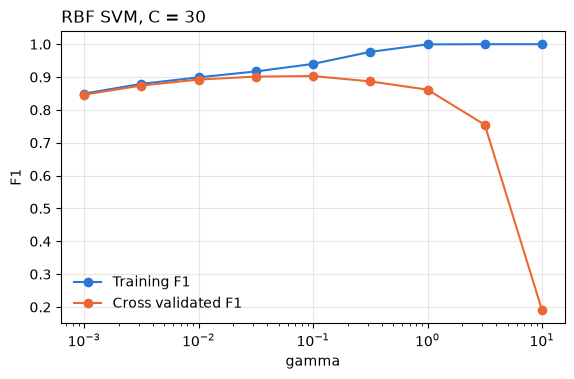

,gamma,train F1,CV F1
0,0.001,0.850,0.846
1,0.003,0.879,0.874
2,0.010,0.899,0.892
3,0.032,0.917,0.901
4,0.100,0.940,0.903
5,0.316,0.977,0.887
6,1.000,0.999,0.862
7,3.162,1.000,0.755
8,10.000,1.000,0.190


In [19]:
gammas = np.logspace(-3, 1, 9)
rbf_C = best["RBF SVM"]["model"].C
train_sc, val_sc = validation_curve(make_pipe(SVC(kernel="rbf", C=rbf_C)), X_train, y_train,
                                    param_name="model__gamma", param_range=gammas,
                                    scoring="f1", cv=cv, n_jobs=-1, groups=stars[train])
plt.figure(figsize=(6.5, 3.8))
plt.plot(gammas, train_sc.mean(1), marker="o", color="#2a78d6", label="Training F1")
plt.plot(gammas, val_sc.mean(1), marker="o", color="#eb6834", label="Cross validated F1")
plt.xscale("log"); plt.xlabel("gamma"); plt.ylabel("F1")
plt.title(f"RBF SVM, C = {rbf_C}", loc="left"); plt.legend(frameon=False); plt.grid(alpha=.3)
plt.show()
pd.DataFrame({"gamma": gammas, "train F1": train_sc.mean(1), "CV F1": val_sc.mean(1)}).round(3)

**Generalization.** In the main table, logistic regression and the linear SVM have nearly the same train, CV, and test F1 (about 0.81 everywhere). They aren't overfitting, but they have high bias, since a straight line just can't fit this data. The RBF SVM has a bigger train to test gap (0.935 vs 0.898), so it has more variance, but its test score is still much higher. The curve shows the tradeoff: as gamma grows, training F1 climbs all the way to 1.0, while cross validated F1 peaks around gamma = 0.03 to 0.1 and then falls apart (0.30 at gamma = 10, where the model is just memorizing points). The tuned value of 0.1 sits right at the peak. We'd pick the RBF SVM for accuracy, and logistic regression if we needed something fast and simple that behaves the same on new data.

## Which variables are predictive?

Logistic regression coefficients are hard to read here because several features are calculated from each other. For example, insolation, temperature, and period are tied together. Permutation importance works for any model: we shuffle one column in the test set and measure how much F1 drops.

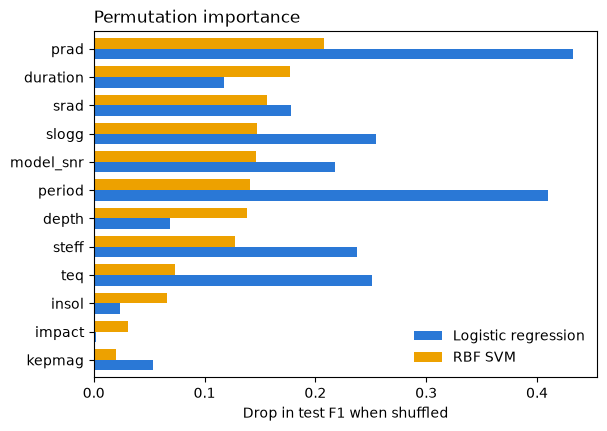

,Logistic regression,RBF SVM
prad,0.433,0.208
duration,0.117,0.177
srad,0.178,0.156
slogg,0.255,0.148
model_snr,0.218,0.147
period,0.410,0.141
depth,0.069,0.138
steff,0.238,0.128
teq,0.252,0.073
insol,0.023,0.066


In [21]:
COLORS = {"Logistic regression": "#2a78d6", "Linear SVM": "#eb6834", "Polynomial SVM": "#1baf7a", "RBF SVM": "#eda100"}
imp = {}
for name in ["Logistic regression", "RBF SVM"]:
    r = permutation_importance(best[name], X_test, y_test, scoring="f1", n_repeats=10, random_state=SEED, n_jobs=-1)
    imp[name] = r.importances_mean
imp = pd.DataFrame(imp, index=[f.replace("koi_", "") for f in FEATURES]).sort_values("RBF SVM")

ax = imp.plot.barh(figsize=(6.5, 4.5), color=[COLORS[c] for c in imp.columns], width=.75)
ax.set_xlabel("Drop in test F1 when shuffled"); ax.set_title("Permutation importance", loc="left")
ax.legend(frameon=False); plt.show()
imp.sort_values("RBF SVM", ascending=False).round(3)

**Which variables matter?** The two models use the data differently. Logistic regression leans heavily on planet radius (0.41) and insolation (0.44), with period, signal to noise, and surface gravity next. The RBF SVM spreads its importance much more evenly across duration, radius, depth, signal to noise, and stellar radius, all around 0.15 to 0.18. That fits what a curved model can do: planet radius is basically transit depth combined with stellar radius, so the RBF SVM can get that information from depth and stellar radius together, while logistic regression needs the precomputed radius column. Impact parameter and Kepler magnitude (star brightness) matter least for both. One caveat is that shuffling a column that's strongly correlated with another can understate its importance, because the model can partly fall back on the correlated one.

## A pair of variables and the decision boundary

We refit each model using only signal to noise and transit duration (both log scaled), so we can plot the boundary in two dimensions. This is just for building intuition. The full models use all 12 features.

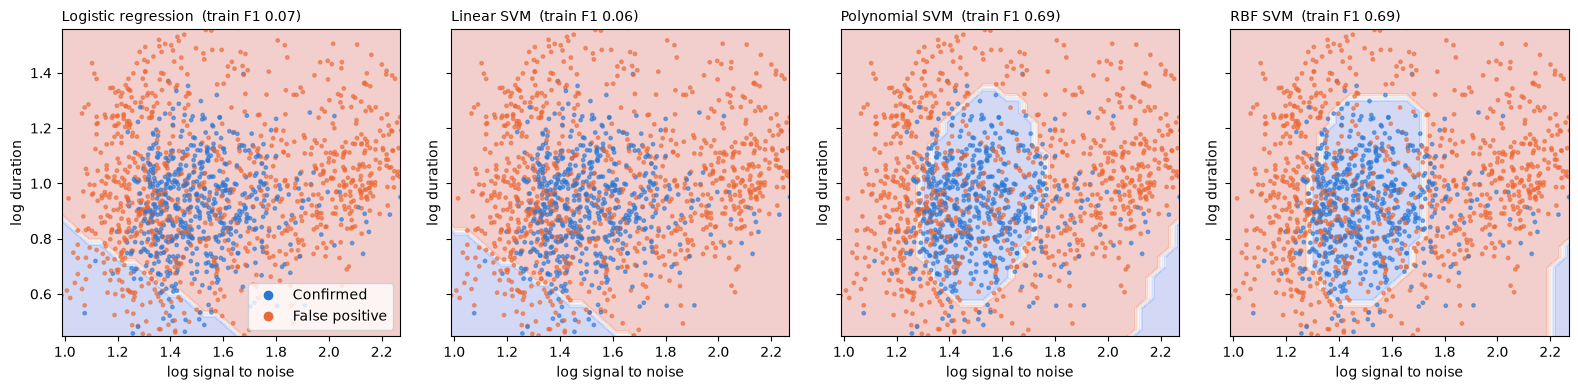

In [22]:
pair = ["koi_model_snr", "koi_duration"]
X2 = X_train[pair].to_numpy()
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
show = np.random.default_rng(SEED).choice(len(X2), 1500, replace=False)
for ax, (name, m) in zip(axes, best.items()):
    m2 = make_pipe(m["model"]).fit(X2, y_train)
    DecisionBoundaryDisplay.from_estimator(m2, X2, response_method="predict", ax=ax, alpha=.25, cmap="coolwarm_r",
                                           xlabel="log signal to noise", ylabel="log duration")
    ax.scatter(X2[show, 0], X2[show, 1], c=np.where(y_train[show] == 1, "#2a78d6", "#eb6834"), s=6, alpha=.6)
    ax.set_title(f"{name}  (train F1 {f1_score(y_train, m2.predict(X2)):.2f})", loc="left", fontsize=10)
    ax.set_xlim(np.percentile(X2[:, 0], [.5, 99.5])); ax.set_ylim(np.percentile(X2[:, 1], [.5, 99.5]))
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color="#2a78d6", label="Confirmed"),
                        plt.Line2D([], [], marker="o", ls="", color="#eb6834", label="False positive")], frameon=True)
plt.tight_layout(); plt.show()

**The decision boundary.** This plot shows why the curved models win. Confirmed planets sit in the middle of the signal to noise range, and false positives surround them on both sides: weak signals on the left and very strong ones (often eclipsing stars) on the right. A straight line can't fence in a middle region, so with only these two features logistic regression and the linear SVM end up calling almost everything a false positive (train F1 0.13 and 0.10). Both kernel SVMs draw a closed region around the planets and reach F1 0.69 from just two variables. The small extra region in the polynomial SVM's bottom right corner is an artifact of the polynomial shape, not something the data supports.